# NASA C-MAPSS FD001: exploratory data analysis

Purpose: understand the FD001 turbofan data before any modelling, and decide how to clean it.

**Files expected** (set the `FD001_DATA_DIR` environment variable, or put them in `data/raw/`):
`train_FD001.txt`, `test_FD001.txt`, `RUL_FD001.txt`.

**Sections**
1. Load, checksum and validate the raw files
2. Overview and RUL labels
3. Engine lifetimes
4. Engine-separated split (done *before* any profiling, to avoid leakage)
5. Column profile: which columns to drop, keep or review
6. Sensor behaviour as engines approach failure
7. Correlations and redundancy
8. Engine-to-engine offsets versus degradation
9. Causal rolling features preview
10. Test versus train domain check
11. Cleaning recommendations and saved manifest

Everything that informs a modelling decision (sections 5 to 9) uses **development engines only**. The validation engines and the official test set stay untouched.

Figures quoted in the companion column guide come from general knowledge of C-MAPSS. This notebook measures them on your copy, so trust the notebook output over the guide where they differ.

In [1]:
import sys; 
print(sys.executable)

/Users/joseph/Desktop/RUL_prediction/.venv/bin/python


In [1]:
import hashlib
import json
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from IPython.display import display

# ---- configuration -------------------------------------------------------
SEED = 42                       # fixed seed for the engine split
N_VALIDATION_ENGINES = 20       # 80 / 20 split when the source has 100 engines
TREND_MIN_RHO = 0.5             # heuristic: median per-engine |Spearman| with cycle
TREND_MIN_CONSISTENCY = 0.8     # heuristic: share of engines trending the same way
SAVE_OUTPUTS = True             # writes a small JSON manifest under artifacts/eda/

# ---- palette: grey context plus blue / orange / purple (checked for colour-blind separation and contrast)
INK, MUTED, BLUE, ORANGE, PURPLE = "#1F2933", "#B8BEC6", "#2F6FB5", "#C4660F", "#8A5FB0"
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_orange", [BLUE, "#EDEFF2", ORANGE])

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#E4E7EB", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# ---- schema ----------------------------------------------------------------
ID_COLS = ["engine_id", "cycle"]
SETTING_COLS = [f"setting_{i}" for i in range(1, 4)]
SENSOR_COLS = [f"sensor_{i}" for i in range(1, 22)]
FEATURE_COLS = SETTING_COLS + SENSOR_COLS
RAW_COLS = ID_COLS + FEATURE_COLS
FILES = {"train": "train_FD001.txt", "test": "test_FD001.txt", "rul": "RUL_FD001.txt"}


def find_data_dir():
    env = os.environ.get("FD001_DATA_DIR")
    candidates = [Path(env)] if env else []
    subdirs = ("data/raw/CMAPSS", "data/raw", "data", "TurbofanHPC_RUL_prediction/data/raw/CMAPSS", ".")
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:      # works whichever folder the kernel starts in
        candidates += [base / s for s in subdirs]
    for c in candidates:
        if (c / FILES["train"]).exists():
            return c.resolve()
    raise FileNotFoundError(
        f"Could not find train_FD001.txt (searched from {here}). Put the three FD001 files "
        "in data/raw/CMAPSS/ or set the FD001_DATA_DIR environment variable."
    )


DATA_DIR = find_data_dir()
if DATA_DIR.name == "CMAPSS":
    PROJECT_ROOT = DATA_DIR.parent.parent.parent
elif DATA_DIR.name == "raw" and DATA_DIR.parent.name == "data":
    PROJECT_ROOT = DATA_DIR.parent.parent
else:
    PROJECT_ROOT = Path.cwd()
OUT_DIR = PROJECT_ROOT / "artifacts" / "eda"
print("Data directory:", DATA_DIR)

Data directory: /Users/joseph/Desktop/RUL_prediction/TurbofanHPC_RUL_prediction/data/raw/CMAPSS


## 1. Load, checksum and validate

The raw files are whitespace separated with no header, and each line may end with extra spaces. The loader names the 26 columns and drops extra trailing columns **only if they are entirely empty**.

Validation reports problems instead of repairing them, as the requirements specify (FR01). This notebook warns and carries on so you can still explore; the real pipeline should reject.

In [2]:
def load_fd001(path):
    df = pd.read_csv(path, sep=r"\s+", header=None)
    extra = df.shape[1] - len(RAW_COLS)
    if extra > 0:
        if df.iloc[:, len(RAW_COLS):].isna().all().all():
            df = df.iloc[:, :len(RAW_COLS)]
        else:
            raise ValueError(f"{path.name}: {extra} extra columns contain data, refusing to drop them")
    elif extra < 0:
        raise ValueError(f"{path.name}: expected {len(RAW_COLS)} columns, found {df.shape[1]}")
    df.columns = RAW_COLS
    return df


checksums = {k: hashlib.sha256((DATA_DIR / v).read_bytes()).hexdigest() for k, v in FILES.items()}
train = load_fd001(DATA_DIR / FILES["train"])
test = load_fd001(DATA_DIR / FILES["test"])
rul_test = pd.read_csv(DATA_DIR / FILES["rul"], sep=r"\s+", header=None, names=["rul_cycles"])

display(pd.Series(checksums, name="sha256"))


def validate_frame(df, label):
    rows = []

    def add(check, ok, detail=""):
        rows.append({"dataset": label, "check": check, "status": "PASS" if ok else "FAIL", "detail": detail})

    num = df.apply(pd.to_numeric, errors="coerce")
    add("26 columns", df.shape[1] == len(RAW_COLS), f"{df.shape[1]} columns")
    add("no missing values", not df.isna().any().any(), f"{int(df.isna().sum().sum())} missing")
    add("all values finite", bool(np.isfinite(num.to_numpy(dtype=float)).all()), "")
    dup = int(df.duplicated(ID_COLS).sum())
    add("no duplicate (engine_id, cycle)", dup == 0, f"{dup} duplicate rows")
    ids = np.sort(df["engine_id"].unique())
    add("engine ids run 1..N", ids.tolist() == list(range(1, len(ids) + 1)), f"{len(ids)} engines")
    g = df.groupby("engine_id")["cycle"]
    bad = g.apply(lambda s: not (s.min() == 1 and s.max() == len(s) and s.is_monotonic_increasing))
    add("cycles run 1..N per engine, in order", not bad.any(),
        "bad engines: " + ", ".join(map(str, bad[bad].index[:5])) if bad.any() else "")
    return rows


rows = validate_frame(train, "train") + validate_frame(test, "test")
n_test_engines = test["engine_id"].nunique()
rows.append({"dataset": "RUL file", "check": "one value per test engine",
             "status": "PASS" if len(rul_test) == n_test_engines else "FAIL",
             "detail": f"{len(rul_test)} labels for {n_test_engines} test engines"})
rows.append({"dataset": "RUL file", "check": "non-negative, no missing",
             "status": "PASS" if (rul_test["rul_cycles"].notna().all() and (rul_test["rul_cycles"] >= 0).all()) else "FAIL",
             "detail": ""})
report = pd.DataFrame(rows)
display(report)

failed = report[report["status"] == "FAIL"]
if len(failed):
    print(f"WARNING: {len(failed)} validation check(s) failed. Fix the source before modelling.")
else:
    print("All validation checks passed.")

train    963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8...
test     3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf...
rul      a19c8ec94931949d0485bdc35118206e9c81c4547b422e...
Name: sha256, dtype: object

,dataset,check,status,detail
0,train,26 columns,PASS,26 columns
1,train,no missing values,PASS,0 missing
2,train,all values finite,PASS,
3,train,"no duplicate (engine_id, cycle)",PASS,0 duplicate rows
4,train,engine ids run 1..N,PASS,100 engines
5,train,"cycles run 1..N per engine, in order",PASS,
6,test,26 columns,PASS,26 columns
7,test,no missing values,PASS,0 missing
8,test,all values finite,PASS,
9,test,"no duplicate (engine_id, cycle)",PASS,0 duplicate rows


All validation checks passed.


## 2. Overview and RUL labels

The raw files contain **no RUL column**. For training engines, RUL at a row is the engine's final cycle minus the current cycle (FR02). For test engines, only the **last observed cycle** has a label, taken from `RUL_FD001.txt`; the last test cycle is not the failure point.

In [3]:
overview = pd.DataFrame({
    "rows": [len(train), len(test)],
    "engines": [train["engine_id"].nunique(), test["engine_id"].nunique()],
    "min cycles per engine": [train.groupby("engine_id")["cycle"].max().min(), test.groupby("engine_id")["cycle"].max().min()],
    "median cycles per engine": [train.groupby("engine_id")["cycle"].max().median(), test.groupby("engine_id")["cycle"].max().median()],
    "max cycles per engine": [train.groupby("engine_id")["cycle"].max().max(), test.groupby("engine_id")["cycle"].max().max()],
}, index=["train", "test"])
display(overview)
display(train.head())

# ---- derive labels ---------------------------------------------------------
train["rul_cycles"] = train.groupby("engine_id")["cycle"].transform("max") - train["cycle"]

test_ids = np.sort(test["engine_id"].unique())
test_endpoints = pd.DataFrame({
    "last_observed_cycle": test.groupby("engine_id")["cycle"].max().loc[test_ids].to_numpy(),
    "rul_cycles": rul_test["rul_cycles"].to_numpy()[: len(test_ids)],
}, index=pd.Index(test_ids, name="engine_id"))
test_endpoints["implied_total_life"] = test_endpoints["last_observed_cycle"] + test_endpoints["rul_cycles"]

# ---- self-check on a tiny fixture (AT02) ------------------------------------
fx = pd.DataFrame({"engine_id": [1] * 5, "cycle": [1, 2, 3, 4, 5]})
fx_rul = fx.groupby("engine_id")["cycle"].transform("max") - fx["cycle"]
assert fx_rul.iloc[0] == 4 and fx_rul.iloc[-1] == 0, "RUL derivation is wrong"
print("RUL label self-check passed: fixture ending at cycle 5 gives RUL 4 at cycle 1 and 0 at cycle 5.")
display(test_endpoints.head())

,rows,engines,min cycles per engine,median cycles per engine,max cycles per engine
train,20631,100,128,199.0000,362
test,13096,100,31,133.5000,303


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0000,518.6700,641.8200,"1,589.7000","1,400.6000",14.6200,21.6100,554.3600,"2,388.0600","9,046.1900",1.3000,47.4700,521.6600,"2,388.0200","8,138.6200",8.4195,0.0300,392,2388,100.0000,39.0600,23.4190
1,1,2,0.0019,-0.0003,100.0000,518.6700,642.1500,"1,591.8200","1,403.1400",14.6200,21.6100,553.7500,"2,388.0400","9,044.0700",1.3000,47.4900,522.2800,"2,388.0700","8,131.4900",8.4318,0.0300,392,2388,100.0000,39.0000,23.4236
2,1,3,-0.0043,0.0003,100.0000,518.6700,642.3500,"1,587.9900","1,404.2000",14.6200,21.6100,554.2600,"2,388.0800","9,052.9400",1.3000,47.2700,522.4200,"2,388.0300","8,133.2300",8.4178,0.0300,390,2388,100.0000,38.9500,23.3442
3,1,4,0.0007,0.0000,100.0000,518.6700,642.3500,"1,582.7900","1,401.8700",14.6200,21.6100,554.4500,"2,388.1100","9,049.4800",1.3000,47.1300,522.8600,"2,388.0800","8,133.8300",8.3682,0.0300,392,2388,100.0000,38.8800,23.3739
4,1,5,-0.0019,-0.0002,100.0000,518.6700,642.3700,"1,582.8500","1,406.2200",14.6200,21.6100,554.0000,"2,388.0600","9,055.1500",1.3000,47.2800,522.1900,"2,388.0400","8,133.8000",8.4294,0.0300,393,2388,100.0000,38.9000,23.4044


RUL label self-check passed: fixture ending at cycle 5 gives RUL 4 at cycle 1 and 0 at cycle 5.


,last_observed_cycle,rul_cycles,implied_total_life
engine_id,,,
1,31,112,143
2,49,98,147
3,126,69,195
4,106,82,188
5,98,91,189


## 3. Engine lifetimes

Lifetimes vary a lot between engines. That is why per-row error metrics can overweight long-lived engines and why the requirements ask for engine-averaged metrics (FR10). The test panels show how far through their life the test engines were cut off and how much life remained.

,train lifetime,test observed length,test endpoint RUL,test implied total life
count,100.0000,100.0000,100.0000,100.0000
mean,206.3100,130.9600,75.5200,206.4800
std,46.3427,53.5935,41.7650,44.0419
min,128.0000,31.0000,7.0000,141.0000
25%,177.0000,88.7500,32.7500,174.7500
50%,199.0000,133.5000,86.0000,199.0000
75%,229.2500,164.2500,112.2500,227.7500
max,362.0000,303.0000,145.0000,341.0000


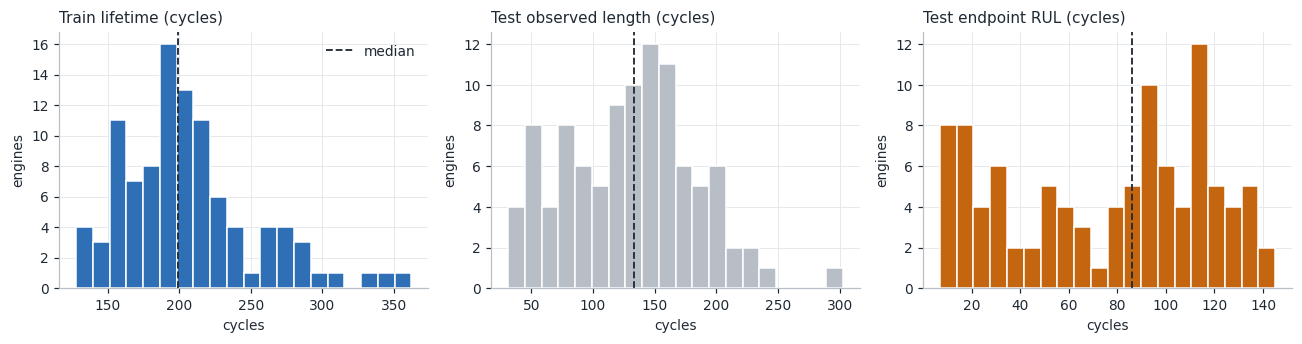

In [4]:
train_life = train.groupby("engine_id")["cycle"].max()
display(pd.DataFrame({
    "train lifetime": train_life.describe(),
    "test observed length": test_endpoints["last_observed_cycle"].describe(),
    "test endpoint RUL": test_endpoints["rul_cycles"].describe(),
    "test implied total life": test_endpoints["implied_total_life"].describe(),
}))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
panels = [
    (train_life, "Train lifetime (cycles)", BLUE),
    (test_endpoints["last_observed_cycle"], "Test observed length (cycles)", MUTED),
    (test_endpoints["rul_cycles"], "Test endpoint RUL (cycles)", ORANGE),
]
for ax, (values, title, color) in zip(axes, panels):
    ax.hist(values, bins=20, color=color, edgecolor="white", linewidth=1.0)
    ax.axvline(values.median(), color=INK, lw=1.2, ls="--")
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("cycles")
    ax.set_ylabel("engines")
axes[0].legend(handles=[Line2D([0], [0], color=INK, lw=1.2, ls="--", label="median")], frameon=False)
plt.tight_layout()
plt.show()

## 4. Engine-separated split

Rows from one engine look almost identical to their neighbours, so a random row split would leak. This splits **whole engines** with a fixed seed (FR03). From here on, profiling uses only the development engines (`dev`).

In [5]:
rng = np.random.default_rng(SEED)
all_train_ids = np.sort(train["engine_id"].unique())
val_ids = np.sort(rng.choice(all_train_ids, size=N_VALIDATION_ENGINES, replace=False))
dev_ids = np.setdiff1d(all_train_ids, val_ids)
assert set(val_ids).isdisjoint(set(dev_ids)), "development and validation engines overlap"

dev = train[train["engine_id"].isin(dev_ids)].copy()
print(f"Seed {SEED}: {len(dev_ids)} development engines, {len(val_ids)} validation engines.")
print("Validation engine ids:", val_ids.tolist())
print(f"Development rows: {len(dev):,}")

Seed 42: 80 development engines, 20 validation engines.
Validation engine ids: [8, 9, 13, 18, 37, 46, 48, 50, 55, 62, 64, 69, 72, 74, 76, 84, 85, 87, 90, 95]
Development rows: 16,390


## 5. Column profile: drop, keep or review

For each setting and sensor this reports basic statistics, then a **per-engine trend**: the Spearman correlation between the column and cycle, computed inside each engine and summarised across engines. A useful degradation sensor trends the same way in most engines.

Verdict rules (heuristics, set at the top of the notebook):
- `drop: constant` when the standard deviation is zero.
- `review: near-constant` when the column takes five or fewer distinct values. (Spread relative to the mean is a poor test here: fan and core speed sensors sit near 2,388 rpm and barely move in relative terms, yet can still trend.)
- `keep: consistent trend` when the median per-engine |rho| is at least `TREND_MIN_RHO` and at least `TREND_MIN_CONSISTENCY` of engines trend in the same direction.
- `review: weak or inconsistent trend` otherwise.

Treat `review` columns as candidates to test with the model, not as automatic drops.

In [6]:
stats = dev[FEATURE_COLS].agg(["mean", "std", "min", "max", "nunique"]).T

trend_rows = {}
for eid, g in dev.groupby("engine_id"):
    ranks = g[FEATURE_COLS].rank()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with np.errstate(all="ignore"):
            trend_rows[eid] = ranks.corrwith(g["cycle"])
trend = pd.DataFrame(trend_rows).T  # engines x columns

profile = stats.copy()
profile["median_rho"] = trend.median()
same_sign = np.sign(trend).eq(np.sign(trend.median()))
profile["sign_consistency"] = same_sign.mean().where(profile["std"] > 1e-12)


def verdict(row):
    if row["std"] < 1e-12:
        return "drop: constant"
    if row["nunique"] <= 5:
        return "review: near-constant"
    if abs(row["median_rho"]) >= TREND_MIN_RHO and row["sign_consistency"] >= TREND_MIN_CONSISTENCY:
        return "keep: consistent trend"
    return "review: weak or inconsistent trend"


profile["verdict"] = profile.apply(verdict, axis=1)
display(profile[["mean", "std", "min", "max", "nunique", "median_rho", "sign_consistency", "verdict"]])

drop_cols = profile.index[profile["verdict"].str.startswith("drop")].tolist()
review_cols = profile.index[profile["verdict"].str.startswith("review")].tolist()
keep_cols = profile.index[profile["verdict"].str.startswith("keep")].tolist()
keep_sensors = [c for c in keep_cols if c.startswith("sensor")]
print("Drop  :", drop_cols)
print("Review:", review_cols)
print("Keep  :", keep_cols)

,mean,std,min,max,nunique,median_rho,sign_consistency,verdict
setting_1,-0.0000,0.0022,-0.0087,0.0083,157.0000,-0.0063,0.5625,review: weak or inconsistent trend
setting_2,0.0000,0.0003,-0.0006,0.0006,13.0000,0.0100,0.5750,review: weak or inconsistent trend
setting_3,100.0000,0.0000,100.0000,100.0000,1.0000,NaN,NaN,drop: constant
sensor_1,518.6700,0.0000,518.6700,518.6700,1.0000,NaN,NaN,drop: constant
sensor_2,642.6803,0.5028,641.2100,644.5300,306.0000,0.6746,1.0000,keep: consistent trend
sensor_3,"1,590.5045",6.1629,"1,571.0400","1,616.9100","2,908.0000",0.6409,1.0000,keep: consistent trend
sensor_4,"1,408.9005",9.0455,"1,382.2500","1,441.4900","3,897.0000",0.7878,1.0000,keep: consistent trend
sensor_5,14.6200,0.0000,14.6200,14.6200,1.0000,NaN,NaN,drop: constant
sensor_6,21.6098,0.0014,21.6000,21.6100,2.0000,0.1332,0.6125,review: near-constant
sensor_7,553.3728,0.8884,549.8500,556.0600,498.0000,-0.7762,1.0000,keep: consistent trend


Drop  : ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Review: ['setting_1', 'setting_2', 'sensor_6', 'sensor_9', 'sensor_14']
Keep  : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 6. Sensor behaviour as engines approach failure

Each panel plots one kept sensor against **cycles before failure**, so every engine ends at zero on the right. Grey lines are all development engines; the coloured lines are the shortest, median and longest-lived engines. If the grey lines fan out at the left and converge towards failure, the sensor carries degradation signal. Large vertical gaps at the left are engine-to-engine baseline offsets.

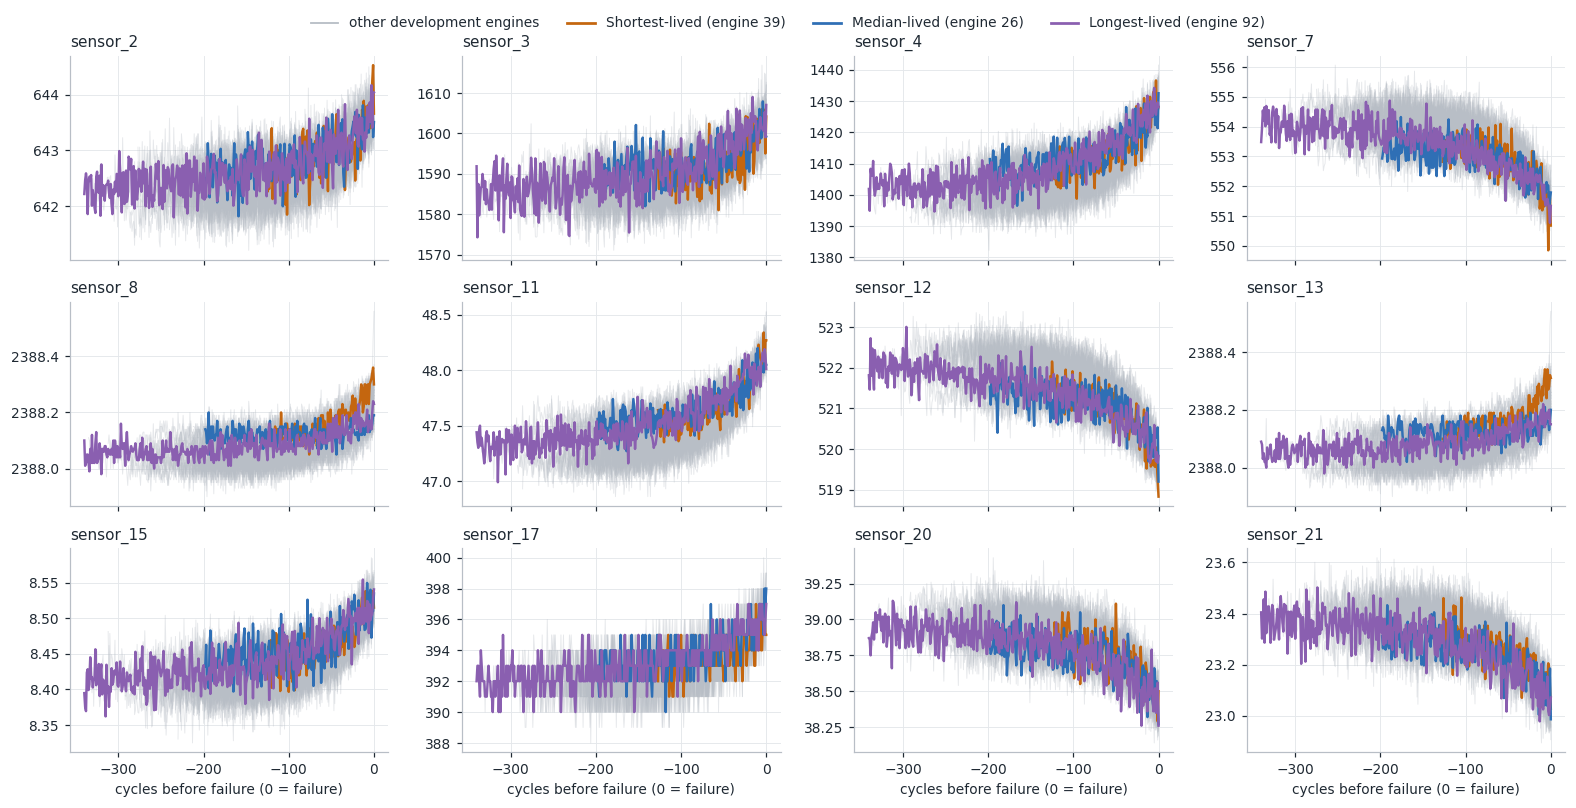

In [7]:
plot_cols = keep_sensors if keep_sensors else [c for c in SENSOR_COLS if c not in drop_cols]
life_dev = dev.groupby("engine_id")["cycle"].max()
focus = {
    "Shortest-lived": life_dev.idxmin(),
    "Median-lived": (life_dev - life_dev.median()).abs().idxmin(),
    "Longest-lived": life_dev.idxmax(),
}
focus_colors = {"Shortest-lived": ORANGE, "Median-lived": BLUE, "Longest-lived": PURPLE}

n = len(plot_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.4 * nrows), sharex=True)
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, plot_cols):
    for eid, g in dev.groupby("engine_id"):
        ax.plot(-g["rul_cycles"], g[col], color=MUTED, lw=0.6, alpha=0.35)
    for label, eid in focus.items():
        g = dev[dev["engine_id"] == eid]
        ax.plot(-g["rul_cycles"], g[col], color=focus_colors[label], lw=1.6)
    ax.set_title(col, loc="left", fontsize=10)
    ax.yaxis.get_major_formatter().set_useOffset(False)
for ax in axes[n:]:
    ax.set_visible(False)
for ax in axes[:n][-ncols:]:
    ax.set_xlabel("cycles before failure (0 = failure)")

handles = [Line2D([0], [0], color=MUTED, lw=1.2, label="other development engines")]
handles += [Line2D([0], [0], color=focus_colors[k], lw=1.8, label=f"{k} (engine {focus[k]})") for k in focus]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

## 7. Correlations and redundancy

The heatmap shows Spearman correlation between the kept sensors and with RUL (last row and column). Strong sensor-to-sensor correlation means several sensors say the same thing; tree models cope with that, but linear models and importance rankings get unstable. Pairs above 0.95 are listed.

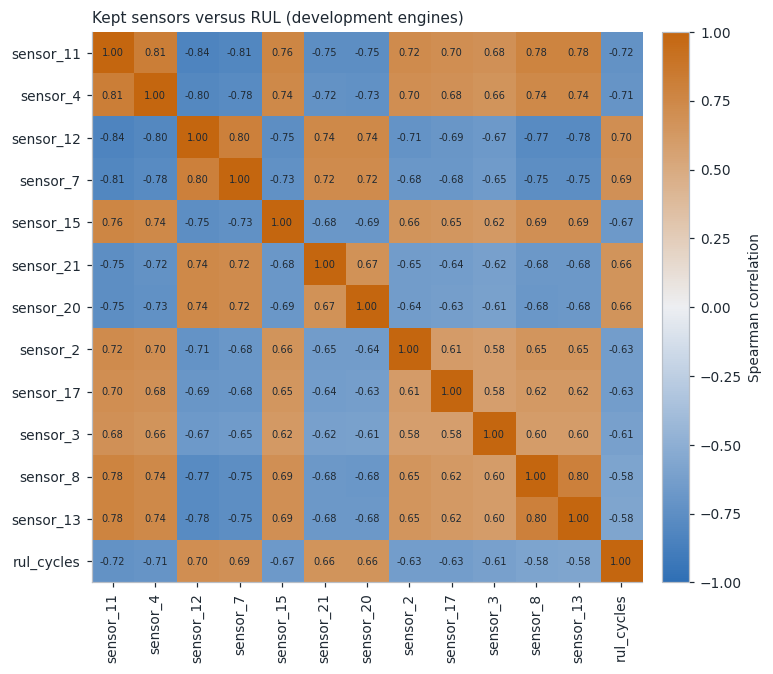

Sensor pairs with |rho| > 0.95: none


,spearman with RUL
sensor_11,-0.7214
sensor_4,-0.7062
sensor_12,0.6956
sensor_7,0.6857
sensor_15,-0.6694
sensor_21,0.6594
sensor_20,0.6568
sensor_2,-0.6335
sensor_17,-0.6332
sensor_3,-0.6135


In [8]:
corr_cols = keep_sensors + ["rul_cycles"]
corr = dev[corr_cols].corr(method="spearman")
order = corr["rul_cycles"].drop("rul_cycles").abs().sort_values(ascending=False).index.tolist() + ["rul_cycles"]
corr = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(corr.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=90)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.grid(False)
for i in range(len(order)):
    for j in range(len(order)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color=INK)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cbar.set_label("Spearman correlation")
ax.set_title("Kept sensors versus RUL (development engines)", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

pairs = []
for i, a in enumerate(order[:-1]):
    for b in order[i + 1:-1]:
        if abs(corr.loc[a, b]) > 0.95:
            pairs.append((a, b, round(float(corr.loc[a, b]), 3)))
print("Sensor pairs with |rho| > 0.95:", pairs if pairs else "none")
display(corr["rul_cycles"].drop("rul_cycles").rename("spearman with RUL").to_frame())

## 8. Engine-to-engine offsets versus degradation

Each engine starts from a slightly different healthy baseline. This compares, for each kept sensor, the **spread of first-cycle values across engines** with the **average change from first to last cycle within an engine**. A ratio below about 1 means baseline differences are larger than the degradation, so a single raw reading is a weak signal and history-based features (rolling statistics, change from an engine's own early baseline) should help.

In [9]:
first = dev.sort_values("cycle").groupby("engine_id")[keep_sensors].first()
last = dev.sort_values("cycle").groupby("engine_id")[keep_sensors].last()
offsets = pd.DataFrame({
    "baseline spread across engines (std of first cycle)": first.std(),
    "mean change over life (|last - first|)": (last - first).abs().mean(),
})
offsets["change / spread"] = offsets.iloc[:, 1] / offsets.iloc[:, 0].replace(0, np.nan)
display(offsets.sort_values("change / spread"))

,baseline spread across engines (std of first cycle),mean change over life (|last - first|),change / spread
sensor_8,0.0538,0.1764,3.2785
sensor_3,4.6002,15.7853,3.4314
sensor_13,0.0521,0.1840,3.5320
sensor_2,0.3592,1.3185,3.6703
sensor_20,0.1413,0.5436,3.8474
sensor_15,0.0267,0.1044,3.9078
sensor_21,0.0787,0.3102,3.9426
sensor_7,0.6494,2.6243,4.0412
sensor_17,1.1363,4.6125,4.0593
sensor_11,0.1984,0.8401,4.2334


## 9. Causal rolling features preview

Rolling mean and standard deviation over the latest 5 and 10 observed rows within one engine (FR05): minimum one observation, `ddof=0`, looking backwards only. The check below confirms that dropping future rows does not change earlier feature values, which is the leakage property in AT03.

,cycle,raw,mean_5,std_5,mean_10,std_10
0,1,47.5600,47.5600,0.0000,47.5600,0.0000
1,2,47.4400,47.5000,0.0600,47.5000,0.0600
2,3,47.6200,47.5400,0.0748,47.5400,0.0748
3,4,47.4800,47.5250,0.0698,47.5250,0.0698


Causality check passed for sensor_11, engine 26: truncating at cycle 99 leaves earlier values unchanged.


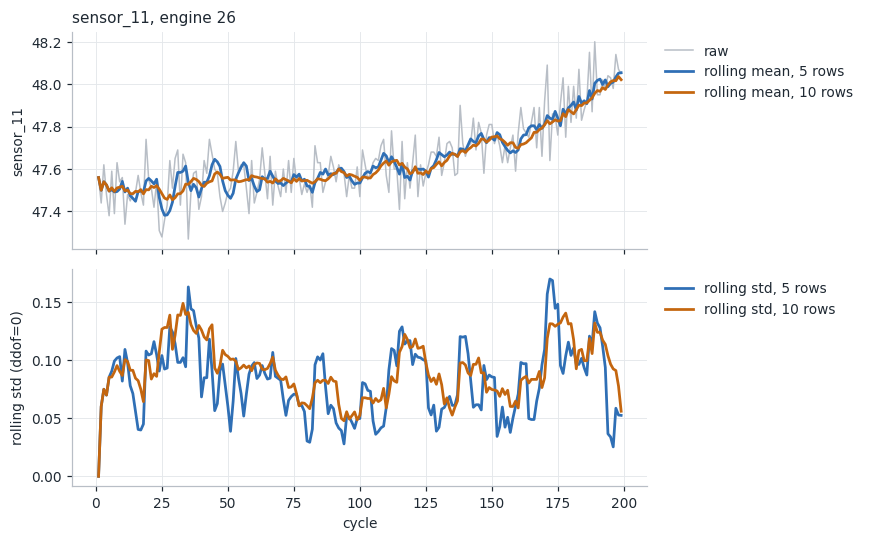

In [10]:
demo_col = profile.loc[keep_sensors, "median_rho"].abs().idxmax() if keep_sensors else SENSOR_COLS[1]
demo_engine = focus["Median-lived"]
g = dev[dev["engine_id"] == demo_engine].sort_values("cycle")
s = g[demo_col].reset_index(drop=True)
cyc = g["cycle"].to_numpy()

feat = pd.DataFrame({"cycle": cyc, "raw": s})
for w in (5, 10):
    feat[f"mean_{w}"] = s.rolling(w, min_periods=1).mean()
    feat[f"std_{w}"] = s.rolling(w, min_periods=1).std(ddof=0)
display(feat.head(4))

cut = len(s) // 2
early_only = s.iloc[:cut].rolling(10, min_periods=1).mean()
full_then_cut = s.rolling(10, min_periods=1).mean().iloc[:cut]
assert np.allclose(early_only, full_then_cut), "rolling feature uses future rows"
print(f"Causality check passed for {demo_col}, engine {demo_engine}: truncating at cycle {cyc[cut - 1]} leaves earlier values unchanged.")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(cyc, feat["raw"], color=MUTED, lw=1.0, label="raw")
axes[0].plot(cyc, feat["mean_5"], color=BLUE, lw=1.8, label="rolling mean, 5 rows")
axes[0].plot(cyc, feat["mean_10"], color=ORANGE, lw=1.8, label="rolling mean, 10 rows")
axes[0].set_ylabel(demo_col)
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[0].set_title(f"{demo_col}, engine {demo_engine}", loc="left", fontsize=10)
axes[0].yaxis.get_major_formatter().set_useOffset(False)
axes[1].plot(cyc, feat["std_5"], color=BLUE, lw=1.8, label="rolling std, 5 rows")
axes[1].plot(cyc, feat["std_10"], color=ORANGE, lw=1.8, label="rolling std, 10 rows")
axes[1].set_ylabel("rolling std (ddof=0)")
axes[1].set_xlabel("cycle")
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(rect=[0, 0, 0.8, 1])
plt.show()

## 10. Test versus train domain check

The test set should sit inside the range the model was developed on. This shows the share of test rows falling outside the training min-max range, per kept column. Small values are normal noise at the edges; large values mean the test engines are operating somewhere the model has not seen.

In [11]:
check_cols = keep_cols if keep_cols else FEATURE_COLS
lo, hi = train[check_cols].min(), train[check_cols].max()
outside = ((test[check_cols] < lo) | (test[check_cols] > hi)).mean() * 100
display(outside.rename("% of test rows outside train range").to_frame().sort_values(
    "% of test rows outside train range", ascending=False))

,% of test rows outside train range
sensor_3,0.0229
sensor_12,0.0229
sensor_2,0.0153
sensor_11,0.0153
sensor_21,0.0153
sensor_8,0.0076
sensor_4,0.0000
sensor_7,0.0000
sensor_13,0.0000
sensor_15,0.0000


## 11. Cleaning recommendations and saved manifest

What this data needs, in order:

1. Keep the raw files untouched; record checksums (done above).
2. Parse with a whitespace separator and a fixed 26-column header.
3. Validate and report problems instead of silently dropping rows.
4. Derive RUL labels; attach the supplied endpoint label to each test engine's last row.
5. Split by engine with a fixed seed before fitting anything.
6. Drop constant columns found on development engines only; test the `review` columns with the model.
7. Do not clip or remove noisy rows; the extreme readings near failure are the signal.
8. Fit any scaler on development engines only.
9. Build rolling features causally, with identical code for training and serving.

In [13]:
print("Recommended handling from this run")
print("-" * 50)
print(f"Engines: {train['engine_id'].nunique()} train, {test['engine_id'].nunique()} test")
print(f"Train lifetime: min {int(train_life.min())}, median {train_life.median():.0f}, max {int(train_life.max())} cycles")
print(f"Drop (constant)  : {drop_cols}")
print(f"Review           : {review_cols}")
print(f"Keep (trending)  : {keep_cols}")
if keep_sensors:
    strongest = profile.loc[keep_sensors, "median_rho"].abs().sort_values(ascending=False).head(5)
    print("Strongest per-engine trends:", {k: round(float(v), 2) for k, v in strongest.items()})

manifest = {
    "seed": SEED,
    "source_checksums_sha256": checksums,
    "development_engine_ids": [int(i) for i in dev_ids],
    "validation_engine_ids": [int(i) for i in val_ids],
    "drop_constant": drop_cols,
    "review": review_cols,
    "keep": keep_cols,
    "thresholds": {"trend_min_rho": TREND_MIN_RHO, "trend_min_consistency": TREND_MIN_CONSISTENCY},
}
if SAVE_OUTPUTS:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    path = OUT_DIR / "eda_split_and_columns.json"
    path.write_text(json.dumps(manifest, indent=2))
    print("\nSaved manifest:", path)

Recommended handling from this run
--------------------------------------------------
Engines: 100 train, 100 test
Train lifetime: min 128, median 199, max 362 cycles
Drop (constant)  : ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Review           : ['setting_1', 'setting_2', 'sensor_6', 'sensor_9', 'sensor_14']
Keep (trending)  : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Strongest per-engine trends: {'sensor_11': 0.82, 'sensor_12': 0.8, 'sensor_4': 0.79, 'sensor_7': 0.78, 'sensor_8': 0.77}

Saved manifest: /Users/joseph/Desktop/RUL_prediction/TurbofanHPC_RUL_prediction/artifacts/eda/eda_split_and_columns.json
